# Review 2 — Text Mining

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Image, Markdown
ROOT=next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'config.yaml').exists())
TS=ROOT/'reports/review2/ts'
TEXT=ROOT/'reports/review2/text'
def table(path):
    frame=pd.read_csv(ROOT/path)
    display(frame)
    return frame
def figure(path): display(Image(filename=str(ROOT/path)))


## Unit 3 — Method 2: Text Mining
M2 Rishiikesh: corpus, tone and complexity. M4 Nishanth: original topic and keyword implementation. The corrections branch replaces the old topic comparison with measured runs; original contributions remain attributed in Git history.

### Preparation: prose, sampling and disjoint topic reference
Remove code from the topic prose; preserve technical vocabulary. VADER uses original prose rather than lowercase topic text. Topic training is stratified by half-year; held-out coherence documents are disjoint. NMF uses TF-IDF, LDA uses counts over the same vocabulary and training IDs. Shares and rates retain sampling weights.

In [2]:
display(json.loads((TEXT/'corpus_stats.json').read_text()))
grid=json.loads((TEXT/'topic_grid_manifest.json').read_text());assert grid['status']=='complete'
display(grid)
split=pd.read_csv(TEXT/'topic_split_manifest.csv')
print(split.groupby('split').size())
assert split.question_id.is_unique
display(json.loads((TEXT/'tone_method.json').read_text()))

{'documents_before': 302026,
 'documents_after': 302026,
 'empty_after_cleaning': 0,
 'vocabulary_size': 165887,
 'total_tokens': 14312333,
 'spacy_model': 'en_core_web_sm',
 'parser_ner': 'disabled',
 'code_excluded': True,
 'sampling_weight': 'retained, must be used in shares',
 'seconds': 418.75}

{'status': 'complete',
 'fingerprint': 'cc9e6a857d7fbc3f4435b8f4dd1f21e3b32f614205729df0ae4cc1883b1c15bb',
 'method_version': 'measured-grid-v1',
 'training_rows': 75814,
 'reference_rows': 20000,
 'vocabulary_size': 22908,
 'seeds': [42, 43, 44],
 'k_values': [10, 15, 20, 25, 30, 40],
 'same_training_sample_for_both_models': True,
 'coherence': 'Exact document-cooccurrence NPMI on top 10 terms; not sliding-window NPMI',
 'selection_rule': 'Highest mean coherence with mean diversity >= 0.7 and stability >= 0.6; otherwise best coherence',
 'iteration_budgets': {'NMF': 400, 'LDA': 10},
 'python': '3.14.8',
 'sklearn': '1.9.1',
 'started_utc': '2026-10-18T15:57:54.210762+00:00',
 'fits': 36,
 'completed_utc': '2026-10-18T16:27:31.863720+00:00',
 'runtime_packages': {'numpy': '2.5.4',
  'scipy': '1.18.1',
  'pandas': '3.0.6',
  'scikit-learn': '1.9.1',
  'joblib': '1.6.0'},
 'automatic_label_update': 'Readable descriptions and mixed screenshot-boilerplate flag from current top terms; no mo

split
coherence_reference    20000
training               75814
dtype: int64


{'technical_word_overrides': ['kill',
  'fatal',
  'execute',
  'master',
  'abort',
  'dead',
  'failed',
  'exception',
  'error'],
 'frustration_regex': '\\burgent\\b|\\basap\\b|\\bstuck\\b|\\bfrustrat\\w*\\b|\\bfor (?:hours|days)\\b|\\bdesperate\\b|\\bnothing works\\b|\\bplease help\\b',
 'politeness_regex': '\\bthanks\\b|\\bthank you\\b|\\bappreciat\\w*\\b',
 'thresholds': {'positive': '>=0.05',
  'negative': '<=-0.05',
  'neutral': 'otherwise'},
 'label_rule': "Label the human asker's emotional tone as negative (expressed frustration/anger/distress), positive (expressed satisfaction/optimism/gratitude), or neutral (factual technical question without clear emotion). Technical error words alone are neutral. Do not use answer outcomes or the model score. Read the title and original question prose, ignoring code. Label independently before comparing.",
 'code_excluded': True,
 'warning': 'VADER is exploratory until independently human validated; no human labels are generated by code'

### Evaluation: real NMF/LDA comparison, six k values and three seeds
Use exact document-cooccurrence NPMI on the top 10 terms from the same held-out reference. This differs from sliding-window c_npmi and is explicitly documented. Diversity uses top 25 terms; stability uses cross-seed best-match Jaccard. Selection maximises mean coherence among diversity≥0.7 and stability≥0.6, with a documented best-coherence fallback. Do not interpret coherence as accuracy.

,model_family,k,coherence_npmi,coherence_sd,diversity,stability,reconstruction_error,satisfies_rule,fit_seconds,seeds,training_rows,reference_rows,warning_runs
0,NMF,10,-0.043838,0.000000,0.800000,1.000000,268.659973,True,14.542216,3,75814,20000,0
1,NMF,15,-0.027001,0.005959,0.735111,0.788062,266.980642,True,16.199764,3,75814,20000,0
2,NMF,20,-0.118539,0.014028,0.698000,0.847493,265.430878,False,21.090695,3,75814,20000,0
3,NMF,25,-0.193599,0.008325,0.698667,0.850105,264.159139,False,14.873655,3,75814,20000,0
4,NMF,30,-0.246874,0.014568,0.681778,0.858874,262.986715,False,22.743694,3,75814,20000,0
5,NMF,40,-0.263703,0.006960,0.690333,0.836011,260.765320,False,53.804538,3,75814,20000,0
6,LDA,10,0.097806,0.014052,0.714667,0.367953,NaN,False,265.137353,3,75814,20000,0
7,LDA,15,0.060709,0.077760,0.726222,0.317405,NaN,False,266.998578,3,75814,20000,0
8,LDA,20,0.046982,0.095756,0.724000,0.288852,NaN,False,273.333028,3,75814,20000,0
9,LDA,25,0.025729,0.064568,0.742400,0.276190,NaN,False,273.014001,3,75814,20000,0


,model_family,k,seed,coherence_npmi,diversity,reconstruction_error,fit_seconds,n_iter,fit_warnings
0,NMF,10,42,-0.043838,0.800000,268.659973,5.758299,198,[]
1,NMF,10,43,-0.043838,0.800000,268.659973,4.809191,172,[]
2,NMF,10,44,-0.043838,0.800000,268.659973,3.974725,136,[]
3,NMF,15,42,-0.032922,0.733333,266.989624,4.092633,93,[]
4,NMF,15,43,-0.027077,0.738667,266.982361,8.148009,196,[]
5,NMF,15,44,-0.021004,0.733333,266.969940,3.959122,89,[]
6,NMF,20,42,-0.105142,0.700000,265.426910,2.795082,52,[]
7,NMF,20,43,-0.117354,0.696000,265.397003,12.407599,266,[]
8,NMF,20,44,-0.133122,0.698000,265.468719,5.888015,123,[]
9,NMF,25,42,-0.202354,0.699200,264.129852,4.032083,52,[]


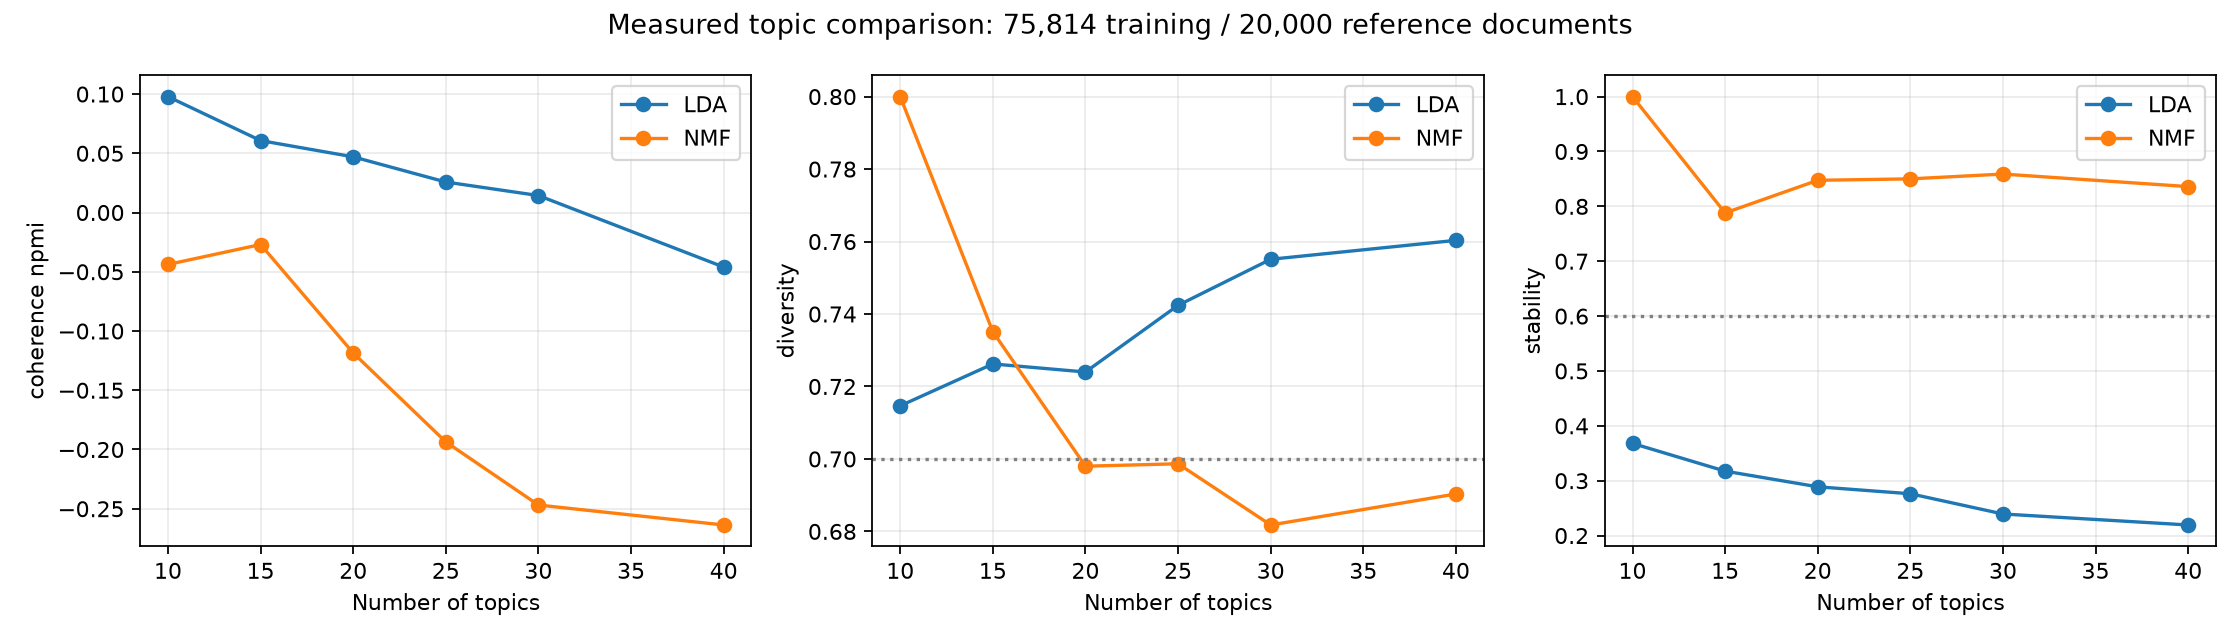

{'status': 'complete',
 'k': 15,
 'model_family': 'NMF',
 'topics_count': 15,
 'corpus_rows': 302026,
 'training_rows': 75814,
 'reference_rows': 20000,
 'zero_projection_documents': 0,
 'fingerprint': 'cc9e6a857d7fbc3f4435b8f4dd1f21e3b32f614205729df0ae4cc1883b1c15bb',
 'seeds': [42, 43, 44],
 'selected_export_seed': 42,
 'label_source': 'automatic term rules; no human naming agreement claimed',
 'top_terms_file': 'topics_top_terms.csv',
 'examples_file': 'topic_examples.csv',
 'labels_file': 'topic_labels.csv',
 'monthly_share_file': 'topic_monthly_share.csv',
 'prepost_file': 'topic_prepost.csv',
 'outcomes_file': 'topic_outcomes.csv',
 'completed_utc': '2026-10-18T16:28:16.698884+00:00'}

Exported NMF k=15 using seed 42


In [3]:
selection=pd.read_csv(TEXT/'topic_model_selection.csv');display(selection)
display(pd.read_csv(TEXT/'topic_model_seed_results.csv'))
figure('reports/review2/text/topic_model_selection.png')
status=json.loads((TEXT/'topics_status.json').read_text());display(status)
print(f"Exported {status['model_family']} k={status['k']} using seed {status['selected_export_seed']}")

### Topic interpretation, weighted prevalence and outcomes
Fifteen terms and ten title-only source examples describe each topic. Topic names are automatic term rules, not independent human ratings. IDs are specific to this fitted model. Zero-vocabulary documents have zero topic weights and no dominant topic. Pre/post differences exclude transition; 1,000 question bootstrap resamples retain survey weights. CI units are absolute share differences (multiply by 100 for pp).

In [4]:
display(pd.read_csv(TEXT/'topic_labels.csv'))
display(pd.read_csv(TEXT/'topics_top_terms.csv').head(30))
display(pd.read_csv(TEXT/'topic_examples.csv').head(20))
display(pd.read_csv(TEXT/'topic_prepost.csv'))
display(pd.read_csv(TEXT/'topic_outcomes.csv'))
display(pd.read_csv(TEXT/'topic_prepost_by_tag.csv').query("tag=='python'"))

,topic,top_terms,name_m4,name_m2,final_name,agreement,label_source,mixed
0,0,"error, python, code, run, function, follow, me...",NaN,NaN,Python errors and package execution,not independently human validated,automatic top-term rules,False
1,1,"column, dataframe, value, row, panda, datum, l...",NaN,NaN,Dataframe rows and columns,not independently human validated,automatic top-term rules,False
2,2,"numbertoken, numbertoken numbertoken, date, ye...",NaN,NaN,Mixed numerical tables and calculations,mixed: automatic suggestion,automatic top-term rules,True
3,3,"button, click, page, html, text, code, change,...",NaN,NaN,User-interface events and elements,not independently human validated,automatic top-term rules,False
4,4,"table, query, sql, row, database, join, record...",NaN,NaN,SQL queries and tables,not independently human validated,automatic top-term rules,False
5,5,"component, react, render, js, state, child, pr...",NaN,NaN,React components and state,not independently human validated,automatic top-term rules,False
6,6,"file, csv, folder, read, excel, csv file, dire...",NaN,NaN,Files and data import/export,not independently human validated,automatic top-term rules,False
7,7,"image, plot, display, image description, enter...",NaN,NaN,"Mixed plotting, images and screenshot boilerplate",mixed: automatic suggestion,automatic top-term rules,True
8,8,"array, object, value, function, return, array ...",NaN,NaN,Arrays and object manipulation,not independently human validated,automatic top-term rules,False
9,9,"android, app, build, studio, device, android s...",NaN,NaN,Android development and builds,not independently human validated,automatic top-term rules,False


,topic,rank,term,weight
0,0,1,error,4.585971
1,0,2,python,2.367038
2,0,3,code,2.305770
3,0,4,run,1.994797
4,0,5,function,1.723624
5,0,6,follow,1.127910
6,0,7,message,0.926605
7,0,8,package,0.909611
8,0,9,script,0.840598
9,0,10,version,0.819442


,topic,question_id,weight,title,link
0,0,54432531,1.0,Error while trying to run a discord bot (python),https://stackoverflow.com/q/54432531
1,0,66194406,1.0,I can't install this repository,https://stackoverflow.com/q/66194406
2,0,72621271,1.0,"Issue with getting robust SEs using Sandwich, ...",https://stackoverflow.com/q/72621271
3,0,62040993,1.0,Errrors while installing NLTK,https://stackoverflow.com/q/62040993
4,0,63621131,1.0,How to solve this error of downloading pyautog...,https://stackoverflow.com/q/63621131
5,0,63643457,1.0,IndentationError: unexpected indent Python 3 E...,https://stackoverflow.com/q/63643457
6,0,74062125,1.0,Warning: NAs introduced by coercionWarning: pr...,https://stackoverflow.com/q/74062125
7,0,74291048,1.0,why I am getting this error even though I have...,https://stackoverflow.com/q/74291048
8,0,70917764,1.0,i need to resolve error highlighted in my ques...,https://stackoverflow.com/q/70917764
9,0,74055242,1.0,R: Error in py_initialize() while using Reticu...,https://stackoverflow.com/q/74055242


,topic,pre_share,post_share,change,change_pct,lower95,upper95,bootstrap_resamples,n_pre,n_post
0,0,0.088282,0.096750,0.008468,9.591909,0.006924,0.010097,1000,207162,87619
1,1,0.097552,0.087197,-0.010355,-10.614566,-0.012421,-0.008139,1000,207162,87619
2,2,0.024154,0.030360,0.006205,25.689028,0.004996,0.007556,1000,207162,87619
3,3,0.097223,0.091891,-0.005333,-5.484876,-0.007171,-0.003393,1000,207162,87619
4,4,0.048188,0.046337,-0.001851,-3.842088,-0.003202,-0.000450,1000,207162,87619
5,5,0.059394,0.059612,0.000218,0.366462,-0.001547,0.001943,1000,207162,87619
6,6,0.074132,0.074645,0.000513,0.691695,-0.001071,0.002368,1000,207162,87619
7,7,0.048809,0.054300,0.005491,11.248981,0.003862,0.007124,1000,207162,87619
8,8,0.077115,0.059097,-0.018017,-23.364306,-0.019565,-0.016550,1000,207162,87619
9,9,0.064990,0.075596,0.010606,16.318725,0.008797,0.012336,1000,207162,87619


,topic,n_questions,resolved_rate_7d,median_hours_to_first_answer
0,0,21863,0.350699,0.835000
1,1,28582,0.583496,0.337222
2,2,8632,0.441890,0.561944
3,3,27998,0.428916,0.643333
4,4,16348,0.469656,0.549444
5,5,17986,0.417079,0.578333
6,6,24274,0.354468,0.942222
7,7,14815,0.400814,1.321111
8,8,18141,0.518656,0.293056
9,9,20626,0.279877,2.414167


,tag,topic,pre_share,post_share,change,change_pct,lower95,upper95,bootstrap_resamples,n_pre,n_post
15,python,0,0.137002,0.151605,0.014602,10.658503,0.010977,0.017946,1000,69208,29503
16,python,1,0.157597,0.127098,-0.030498,-19.352155,-0.034923,-0.025941,1000,69208,29503
17,python,2,0.027758,0.031390,0.003632,13.083823,0.001270,0.005990,1000,69208,29503
18,python,3,0.061113,0.065297,0.004184,6.845767,0.001764,0.006754,1000,69208,29503
19,python,4,0.031192,0.032544,0.001352,4.334077,-0.000359,0.003018,1000,69208,29503
20,python,5,0.008663,0.010416,0.001753,20.239270,0.001107,0.002504,1000,69208,29503
21,python,6,0.098036,0.093588,-0.004448,-4.537256,-0.007927,-0.000876,1000,69208,29503
22,python,7,0.056129,0.060152,0.004023,7.168284,0.001083,0.006855,1000,69208,29503
23,python,8,0.068593,0.061350,-0.007242,-10.558236,-0.009970,-0.004636,1000,69208,29503
24,python,9,0.022918,0.033033,0.010115,44.136395,0.008695,0.011549,1000,69208,29503


### Keywords: Monroe log odds with Dirichlet prior
Compare actual rising and falling terms with effect sizes and frequencies. Technical tokens and templated error language can influence the ranking. Differences describe observed vocabulary, not measured migration to an AI tool.

,term,z_score,log_odds,count_pre,count_post,freq_pre_pct,freq_post_pct,direction,rank,tag_scope
30,array,-129.377801,-0.508737,572357.0,72910.0,0.352219,0.212068,falling,1,ALL
31,list,-96.554035,-0.308974,725562.0,112839.0,0.446499,0.328206,falling,2,ALL
32,object,-94.815447,-0.336136,605313.0,91604.0,0.372500,0.266442,falling,3,ALL
33,dataframe,-81.579975,-0.321950,482602.0,74059.0,0.296986,0.215410,falling,4,ALL
34,like,-80.595917,-0.169530,1489772.0,266423.0,0.916782,0.774924,falling,5,ALL
35,loop,-79.103893,-0.391582,325949.0,46647.0,0.200584,0.135679,falling,6,ALL
36,value,-73.707687,-0.158891,1405902.0,254073.0,0.865170,0.739003,falling,7,ALL
37,string,-71.629604,-0.283485,464217.0,74023.0,0.285672,0.215305,falling,8,ALL
38,jquery,-68.842693,-1.025217,63904.0,4851.0,0.039325,0.014110,falling,9,ALL
39,class,-66.809014,-0.237272,554004.0,92520.0,0.340925,0.269106,falling,10,ALL


,term,z_score,log_odds,count_pre,count_post,freq_pre_pct,freq_post_pct,direction,rank,tag_scope
0,numbertoken,162.913896,0.365067,854016.0,259699.0,0.525548,0.755367,rising,1,ALL
1,numbertoken numbertoken,143.987977,0.493263,331455.0,114695.0,0.203972,0.333605,rising,2,ALL
2,nextjs,126.745964,1.250847,24164.0,17853.0,0.014870,0.051928,rising,3,ALL
3,encounter,122.247692,1.181165,26256.0,18093.0,0.016158,0.052626,rising,4,ALL
4,vite,115.204034,3.393980,1335.0,8411.0,0.000822,0.024464,rising,5,ALL
5,version,102.199695,0.418604,245115.0,78757.0,0.150840,0.229074,rising,6,ALL
6,compose,95.316487,0.728823,56121.0,24601.0,0.034536,0.071555,rising,7,ALL
7,ensure,93.943038,1.139548,17076.0,11289.0,0.010508,0.032835,rising,8,ALL
8,fastapi,89.111478,1.561143,6491.0,6542.0,0.003994,0.019028,rising,9,ALL
9,tailwind,83.647750,1.796807,3866.0,4932.0,0.002379,0.014345,rising,10,ALL


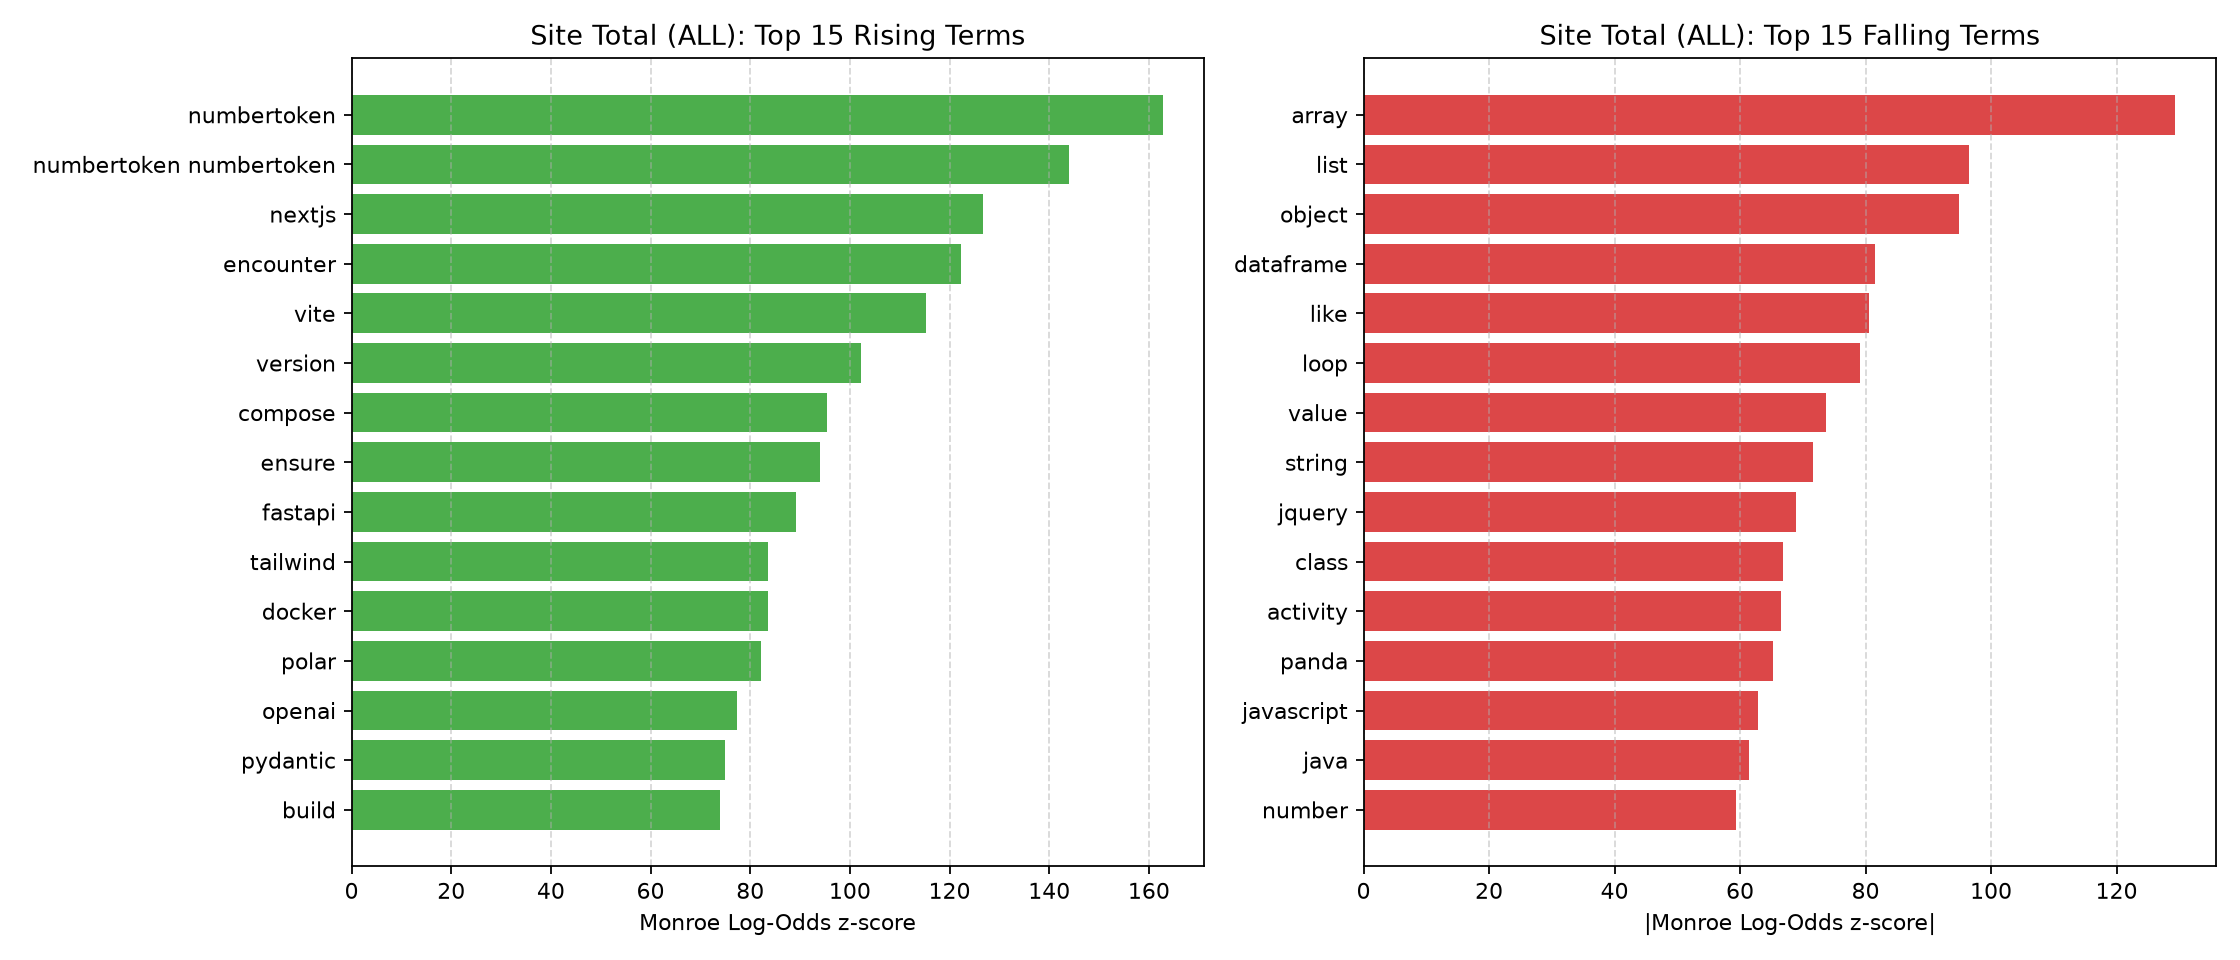

In [5]:
kw=pd.read_csv(TEXT/'keywords_prepost.csv')
display(kw.query("tag_scope=='ALL'").sort_values('z_score').head(10))
display(kw.query("tag_scope=='ALL'").sort_values('z_score',ascending=False).head(10))
figure('reports/review2/text/keywords_shift_all.png')

### Tone validation: one human reference plus disclosed AI annotations
The original two-human protocol was not completed. All 200 existing M3 human labels are used for VADER evaluation. AI labels are separate assistance, not human M2 labels or adjudicated gold. Report VADER accuracy/macro F1 and AI–human agreement/kappa separately. The frustration lexicon is an exploratory phrase proxy, not a reliable detector of a person’s emotion.

In [6]:
display(json.loads((TEXT/'tone_validation_status.json').read_text()))
display(pd.read_csv(TEXT/'tone_validation.csv'))
display(pd.read_csv(TEXT/'tone_confusion.csv'))
display(pd.read_csv(TEXT/'tone_prepost.csv').query("tag=='ALL'"))

{'required_rows': 200,
 'label_m2': 0,
 'label_m3': 200,
 'agreed_tone': 0,
 'accuracy': 0.36,
 'macro_f1': 0.34415857927121324,
 'cohen_kappa': None,
 'human_human_kappa': None,
 'original_two_human_requirement_complete': False,
 'status': 'complete_ai_assisted',
 'labelled_rows': 200,
 'label_ai': 200,
 'reference': 'Akshay/M3 single-human labels; no adjudicated gold standard',
 'ai_human_kappa': 0.2139983157106765,
 'ai_human_agreement': 0.58,
 'ai_macro_f1_vs_human': 0.41704845687077197,
 'annotation_file_sha256': '323267f6fd2e03208247db6a243bbd2268b059c68554fea100d6a545087868fc',
 'limitation': 'AI annotation is not a second independent human rating. Original two-human kappa/adjudication remains unavailable.'}

,required_rows,label_m2,label_m3,agreed_tone,accuracy,macro_f1,cohen_kappa,human_human_kappa,original_two_human_requirement_complete,status,labelled_rows,label_ai,reference,ai_human_kappa,ai_human_agreement,ai_macro_f1_vs_human,annotation_file_sha256,limitation
0,200,0,200,0,0.36,0.344159,NaN,NaN,False,complete_ai_assisted,200,200,Akshay/M3 single-human labels; no adjudicated ...,0.213998,0.58,0.417048,323267f6fd2e03208247db6a243bbd2268b059c68554fe...,AI annotation is not a second independent huma...


,actual,negative,neutral,positive
0,negative,29,0,33
1,neutral,32,8,60
2,positive,2,1,35


,tag,measure,pre,post,change,lower95,upper95,bootstrap_resamples
0,ALL,negative,0.209487,0.236663,0.027176,0.021937,0.032179,1000
1,ALL,neutral,0.079173,0.072314,-0.006858,-0.009828,-0.003590,1000
2,ALL,positive,0.711341,0.691023,-0.020318,-0.025603,-0.015084,1000
3,ALL,frustration,0.050643,0.048570,-0.002073,-0.004611,0.000360,1000
4,ALL,politeness,0.208315,0.178995,-0.029320,-0.033888,-0.024433,1000


### Complexity and uncertainty
Compare weighted prose words, code lines, reading ease and structural flags with 1,000-resample intervals. Reading ease is imperfect for technical prose. Models of resolution associations control for tags/year but do not identify causal effects.

,tag,metric,statistic,pre,post,change,lower95,upper95,n_pre,n_post,bootstrap_resamples
0,ALL,prose_words,median,76.000000,89.000000,13.000000,12.000000,13.000000,207162,87619,1000
1,ALL,code_lines,median,16.000000,20.000000,4.000000,3.000000,4.000000,207162,87619,1000
2,ALL,n_code_blocks,median,1.000000,1.000000,0.000000,0.000000,1.000000,207162,87619,1000
3,ALL,tag_count,median,3.000000,3.000000,0.000000,0.000000,0.000000,207162,87619,1000
4,ALL,flesch_reading_ease,median,67.050000,64.540000,-2.510000,-2.700000,-2.320000,207162,87619,1000
5,ALL,error_text_flag,mean,0.234327,0.274250,0.039923,0.035075,0.045076,207162,87619,1000
6,ALL,why_how_flag,mean,0.260615,0.250686,-0.009928,-0.015069,-0.005014,207162,87619,1000
7,ALL,version_flag,mean,0.076325,0.105564,0.029239,0.025899,0.032733,207162,87619,1000
8,ALL,multi_technology_flag,mean,0.227622,0.194068,-0.033554,-0.038152,-0.028698,207162,87619,1000


,term,coefficient,odds_ratio,lower95,upper95,p_value
0,const,-0.285507,0.751633,0.716941,0.788005,2.375759e-32
1,negative,0.009457,1.009501,0.972887,1.047494,6.158839e-01
2,positive,0.117569,1.124760,1.087836,1.162936,5.072457e-12
3,frustration,-0.189152,0.827661,0.794662,0.862029,8.086101e-20
4,tag_android,-0.367772,0.692275,0.666041,0.719543,1.082109e-77
5,tag_docker,-0.365890,0.693579,0.651427,0.738459,2.717593e-30
6,tag_excel,-0.164189,0.848581,0.801962,0.897911,1.232411e-08
7,tag_fastapi,-0.270024,0.763361,0.724315,0.804513,6.795929e-24
8,tag_java,-0.135807,0.873011,0.841924,0.905246,2.119104e-13
9,tag_javascript,0.112624,1.119211,1.083290,1.156324,1.318443e-11


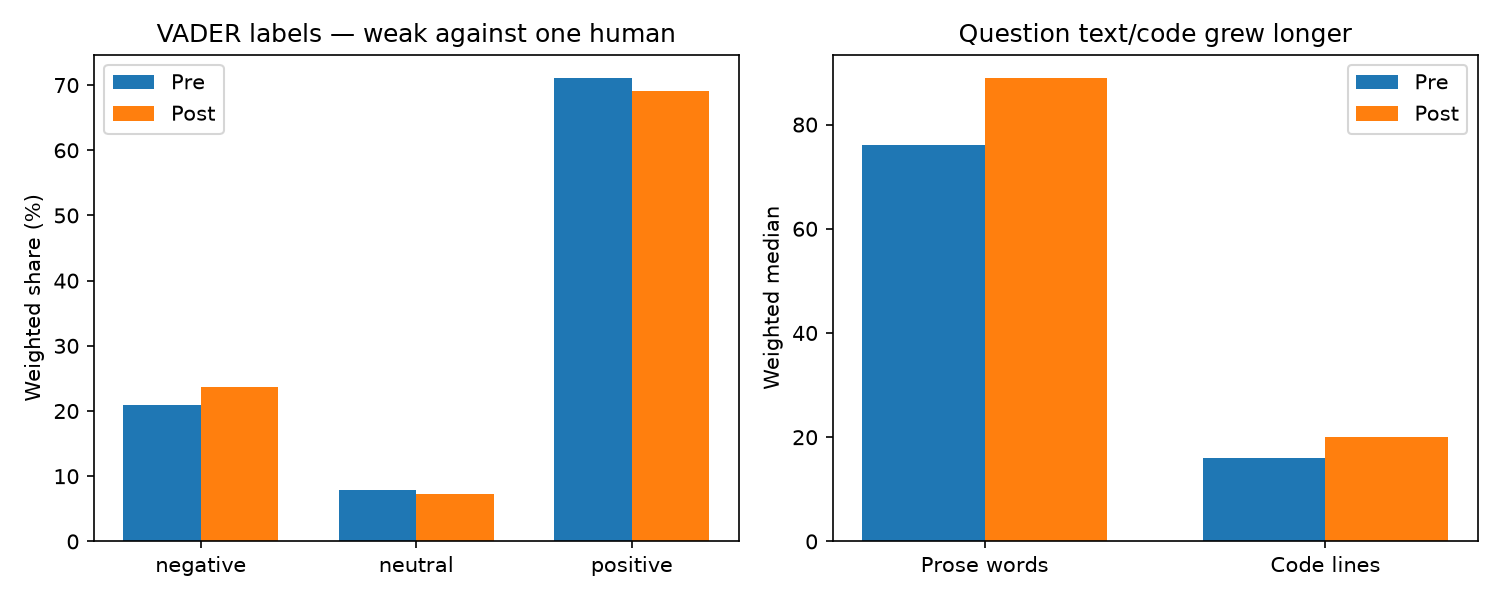

In [7]:
display(pd.read_csv(TEXT/'complexity_prepost.csv').query("tag=='ALL'"))
display(pd.read_csv(TEXT/'tone_resolution_association.csv'))
figure('reports/review2/text/tone_complexity.png')